# Household Electric Power Consumption — 01_Data Cleaning

## Overview
This notebook cleans and prepares the **Individual Household Electric Power Consumption** dataset for exploratory data analysis and time-series modeling.


## Workflow

00. **Import Data**
01. **Data Info.**
02. **Data Type Cleaning**
03. **Missing Values Cleaning**
04. **Duplicates Cleaning**
05. **Export Cleaned Data**

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import missingno as missing

# 00. Import Data

In [5]:
data = pd.read_csv('data/household_power_consumption.txt', delimiter=';', low_memory=False)

# 01. Data Info.

In [6]:
data

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...,...,...
2075254,26/11/2010,20:58:00,0.946,0.000,240.430,4.000,0.000,0.000,0.0
2075255,26/11/2010,20:59:00,0.944,0.000,240.000,4.000,0.000,0.000,0.0
2075256,26/11/2010,21:00:00,0.938,0.000,239.820,3.800,0.000,0.000,0.0
2075257,26/11/2010,21:01:00,0.934,0.000,239.700,3.800,0.000,0.000,0.0


In [7]:
data.shape

(2075259, 9)

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    str    
 3   Global_reactive_power  str    
 4   Voltage                str    
 5   Global_intensity       str    
 6   Sub_metering_1         str    
 7   Sub_metering_2         str    
 8   Sub_metering_3         float64
dtypes: float64(1), str(8)
memory usage: 239.1 MB


| Column | Unit / Type | Description |
| :--- | :--- | :--- |
| **`Date`** | dd/mm/yyyy | Date of the recording. |
| **`Time`** | hh:mm:ss | Time of the recording (sampled every minute). |
| **`Global_active_power`** | Kilowatts (kW) | Total active power consumed by the household (real usable power doing work). |
| **`Global_reactive_power`** | Kilowatts (kW) | Total reactive power consumed (power stored/discharged by inductive or capacitive loads, like motors). |
| **`Voltage`** | Volts (V) | Average minute-by-minute household AC voltage (typically around 230–240 V). |
| **`Global_intensity`** | Amperes (A) | Average current intensity drawn by the household. |
| **`Sub_metering_1`** | Watt-hours (Wh) | Energy consumed specifically by the **kitchen** (dishwasher, oven, microwave). |
| **`Sub_metering_2`** | Watt-hours (Wh) | Energy consumed specifically by the **laundry room** (washing machine, tumble dryer, refrigerator, light). |
| **`Sub_metering_3`** | Watt-hours (Wh) | Energy consumed by electric heating and climate control (water heater, air conditioner). |

# 02. Data Type Cleaning

In [9]:
data.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [10]:
data['Datetime'] = pd.to_datetime(data['Date'] + ' ' + data['Time'], format='%d/%m/%Y %H:%M:%S')
data = data.drop(columns=['Date', 'Time'])

In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Global_active_power    str           
 1   Global_reactive_power  str           
 2   Voltage                str           
 3   Global_intensity       str           
 4   Sub_metering_1         str           
 5   Sub_metering_2         str           
 6   Sub_metering_3         float64       
 7   Datetime               datetime64[us]
dtypes: datetime64[us](1), float64(1), str(6)
memory usage: 189.7 MB


In [12]:
col = data.pop('Datetime')
data.insert(0, 'Datetime', col)

In [13]:
numeric_cols = [
    'Global_active_power', 'Global_reactive_power', 'Voltage',
    'Global_intensity', 'Sub_metering_1', 'Sub_metering_2'
]

for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce')

In [14]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Datetime               datetime64[us]
 1   Global_active_power    float64       
 2   Global_reactive_power  float64       
 3   Voltage                float64       
 4   Global_intensity       float64       
 5   Sub_metering_1         float64       
 6   Sub_metering_2         float64       
 7   Sub_metering_3         float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 126.7 MB


# 03. Missing Values Cleaning

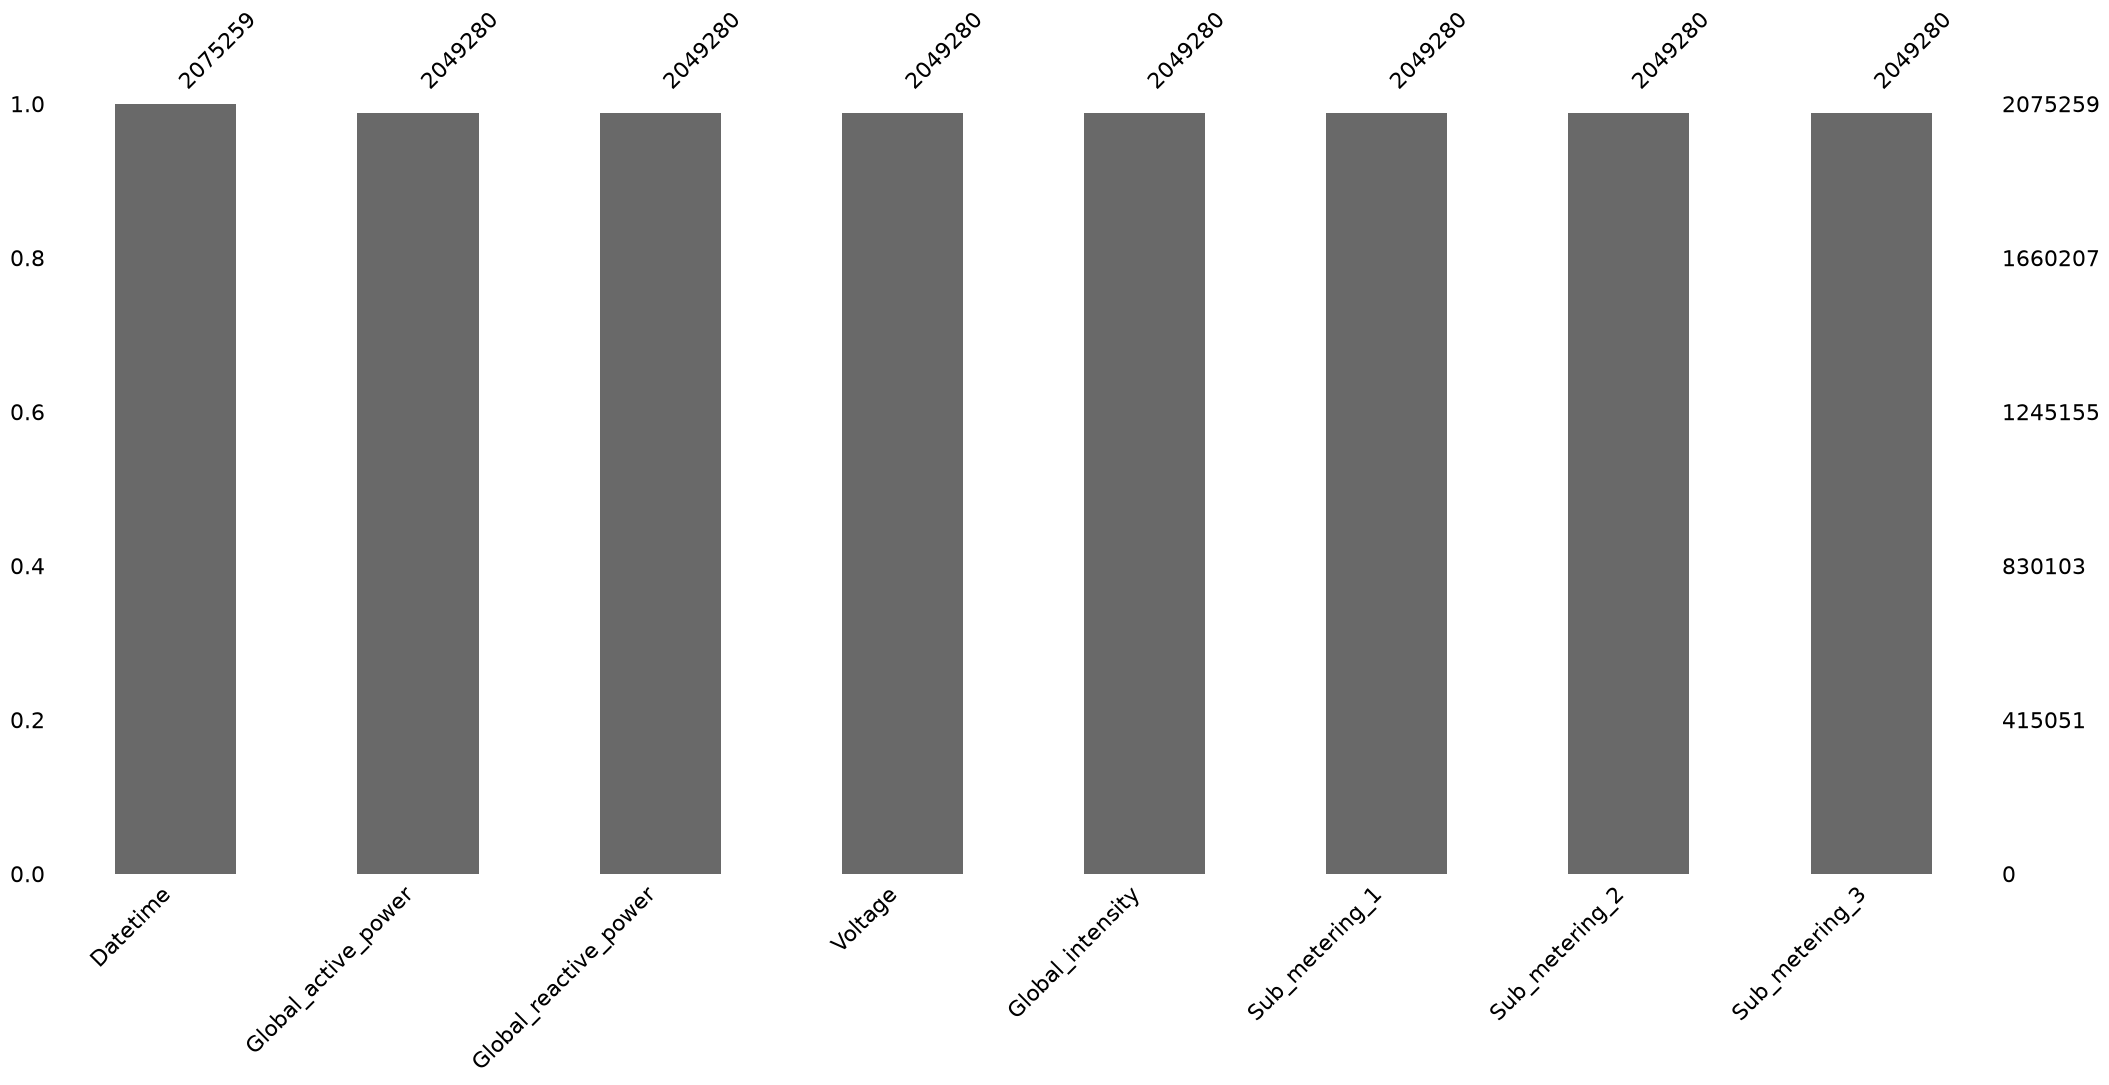

In [15]:
missing.bar(data)
plt.show()

In [16]:
data.isna().sum()

Datetime                     0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [17]:
data[data['Global_active_power'].isna()]

,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
6839,2006-12-21 11:23:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6840,2006-12-21 11:24:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19724,2006-12-30 10:08:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19725,2006-12-30 10:09:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41832,2007-01-14 18:36:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
1990185,2010-09-28 19:09:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1990186,2010-09-28 19:10:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1990187,2010-09-28 19:11:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1990188,2010-09-28 19:12:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
data = data.dropna()

# 04. Duplicates Cleaning

In [19]:
data.duplicated().sum()

np.int64(0)

# 05. Export Cleaned Data

In [20]:
data.info()

<class 'pandas.DataFrame'>
Index: 2049280 entries, 0 to 2075258
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Datetime               datetime64[us]
 1   Global_active_power    float64       
 2   Global_reactive_power  float64       
 3   Voltage                float64       
 4   Global_intensity       float64       
 5   Sub_metering_1         float64       
 6   Sub_metering_2         float64       
 7   Sub_metering_3         float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 140.7 MB


In [21]:
data.to_csv('data/data_cleaned.csv', index=False)